# 05 · Scores of a language model, by reasoning level

**Why.** Notebook 04 saved every game a model played. Here we score those games against the oracle to answer
three questions. How often does the model reach the target, and how close to the optimum does it play? Does more
reasoning help, and at what cost in time? And where do its games go wrong: wrong clicks, needless scrolling, or
clicks on links that are not on the page?

**What.** Two references frame each number. The *random player* picks uniformly among the available actions with
the same step budget, 50 games per task; it is the reference of the bits measure, so it marks what zero skill
looks like. The *people* of Wikispeedia played the same tasks with whole pages visible and no step budget; they
are compared in the clicks model only.

The model's games are sampled, so every number is a mean over the 3 runs of each task. The spread is the range of
the 3 per-run means (each run covers every task once).

**Runtime.** About 20 s, most of it for the random games.

In [1]:
import json, math, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from wikigame.world import World, ROOT
from wikigame.metrics import Graphs, Oracle, score_actions
from wikigame.env import WikiGameEnv
from wikigame.agent import play_random
from wikigame import style
from wikigame.style import INK, INK2, MUTED, AXIS, BLUE, RED, SEQUENTIAL_3

style.use()
MODEL_NAME = "qwen3.8-27b"
LEVELS = ["none", "low", "medium", "xhigh"]
world = World.load("wikispeedia")
g = Graphs.build(world)
tasks = {t["id"]: t for t in json.load(open(world.dir / "tasks" / "index.json"))["tasks"]}
oracles = {t["target"]: Oracle(world, g, t["target"]) for t in tasks.values()}

games = []
for level in LEVELS:
    path = ROOT / "results" / MODEL_NAME / f"effort-{level}.jsonl"
    if path.exists():
        games += [json.loads(line) for line in path.read_text().splitlines()]
print({lvl: sum(1 for x in games if x["reasoning_effort"] == lvl) for lvl in LEVELS}, "games saved")

{'none': 126, 'low': 126, 'medium': 126, 'xhigh': 126} games saved


## One row per game

For each game we keep the actions-model scores (what the model actually did) and the clicks-model scores (the pages
it visited, comparable with people). We also count the kinds of actions it took and the steps with regret, that is
steps that did not bring it one step closer.

In [2]:
def game_row(x):
    t = tasks[x["task"]]
    o = oracles[t["target"]]
    steps, _ = score_actions(o, t["start"], [tuple(a) for a in x["actions"]])
    kinds = pd.Series([a[0] for a in x["actions"]]).value_counts()
    a, c = x["score"]["actions"], x["score"]["clicks"]
    turns = x.get("turns", [])
    return {
        "level": x.get("reasoning_effort", "random"), "task": x["task"], "run": x["run"], "d_star": t["d_star"], "V_star": t["V_star"],
        "success": a["success"], "steps": a["steps"], "max_steps": x.get("max_steps"),
        "efficiency": a["efficiency"], "click_efficiency": c["efficiency"], "clicks": len(x["pages"]) - 1,
        "steps_with_regret": sum(1 for s in steps if not s["optimal"]), "bits_lost": a["bits_lost"],
        "first_error": a["first_error"],
        "scrolls": int(kinds.get("scroll_down", 0) + kinds.get("scroll_up", 0)), "invalid": int(kinds.get("invalid", 0)),
        "seconds": x.get("seconds"), "completion_tokens": sum((u.get("completion_tokens") or 0) for u in turns),
    }

df = pd.DataFrame([game_row(x) for x in games])

rng = random.Random(0)
random_games = []
for t in tasks.values():
    for run in range(50):
        env = WikiGameEnv(world, oracles[t["target"]], t["start"], max_steps=2 * t["V_star"] + 10)
        random_games.append({"task": t["id"], "run": run, "reasoning_effort": "random", "max_steps": env.max_steps, **play_random(env, rng)})
rnd = pd.DataFrame([game_row(x) for x in random_games])
print(len(df), "model games,", len(rnd), "random games")

504 model games, 2100 random games


## Summary by reasoning level

Each line is one reasoning level. *Reached* is the share of games that reached the target within the budget.
*Efficiency* is the fewest actions ÷ actions taken (0 for a game that did not arrive), so it rewards arriving and
arriving fast. *Click efficiency* is the same in the clicks model, over the games that arrived; it is the number to
compare with people. The last columns describe how the model spent its steps, and how long a game took.

In [3]:
def per_run_spread(frame, col):
    per_run = frame.groupby("run")[col].mean()
    return f"{per_run.mean():.2f} [{per_run.min():.2f}–{per_run.max():.2f}]"

def summarise(frame, model=True):
    won = frame[frame.success]
    return pd.Series({
        "games": len(frame),
        "reached": per_run_spread(frame, "success"),
        "efficiency": per_run_spread(frame, "efficiency"),
        "click efficiency (arrived)": f"{won.click_efficiency.mean():.2f}" if len(won) else "–",
        "steps with regret / game": f"{frame.steps_with_regret.mean():.1f}",
        "clicks / game": f"{frame.clicks.mean():.1f}",
        "games with no click": f"{(frame.clicks == 0).mean():.2f}",
        "scrolls / game": f"{frame.scrolls.mean():.1f}",
        "invalid / game": f"{frame.invalid.mean():.2f}",
        "output tokens / step": f"{(frame.completion_tokens.sum() / frame.steps.sum()):.0f}" if model else "–",
        "minutes / game": f"{frame.seconds.mean() / 60:.1f}" if model else "–",
    })

levels_present = [lvl for lvl in LEVELS if lvl in set(df.level)]
summary = pd.DataFrame({lvl: summarise(df[df.level == lvl]) for lvl in levels_present} | {"random player": summarise(rnd, model=False)})
humans = pd.DataFrame([{"task": k, **v} for k, v in tasks.items()]).dropna(subset=["human_success"])
print(f"People (clicks model, no budget, {len(humans)} tasks with human games): finished {humans.human_success.mean():.2f}, "
      f"click efficiency of finished games {humans.human_efficiency.mean():.2f}")
summary

People (clicks model, no budget, 36 tasks with human games): finished 0.70, click efficiency of finished games 0.63


,none,low,medium,xhigh,random player
games,126,126,126,126,2100
reached,0.27 [0.19–0.33],0.25 [0.21–0.29],0.19 [0.17–0.24],0.25 [0.21–0.31],0.03 [0.00–0.07]
efficiency,0.20 [0.13–0.25],0.17 [0.15–0.19],0.15 [0.13–0.17],0.18 [0.17–0.20],0.03 [0.00–0.07]
click efficiency (arrived),0.82,0.85,0.90,0.85,0.91
steps with regret / game,12.9,13.4,14.0,13.6,15.9
clicks / game,3.2,1.7,1.3,1.8,18.7
games with no click,0.18,0.25,0.27,0.22,0.01
scrolls / game,17.5,19.3,20.1,19.0,4.7
invalid / game,0.41,0.31,0.29,0.35,0.00
output tokens / step,10,213,222,355,–


## Success by task length

Tasks are grouped by *d\**, the fewest clicks they need. The model's success at each reasoning level is drawn next
to the random player and to people (who had no step budget, so their success is an upper reference).

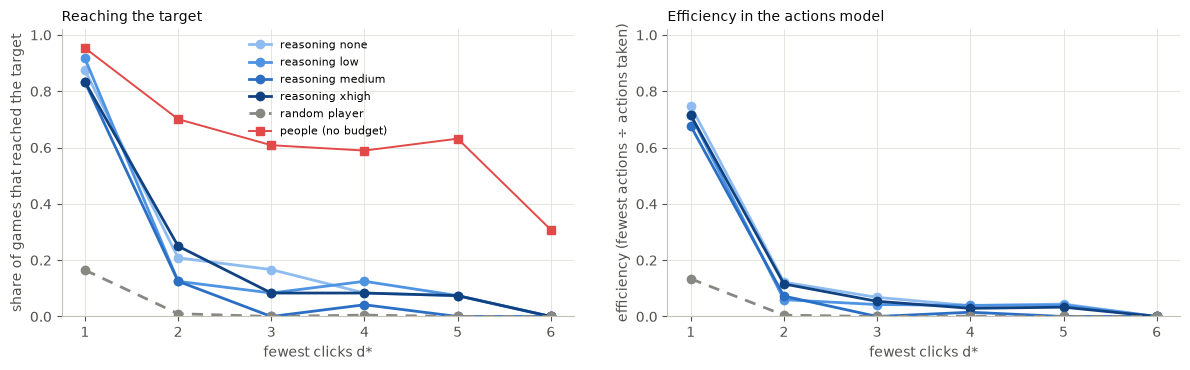

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
by = lambda frame, col: frame.groupby("d_star")[col].mean()
colours = dict(zip(["none", "low", "medium", "xhigh"], ["#8fbcf0", "#4f93e3", "#2a6fc4", "#104281"]))
for lvl in levels_present:
    sub = df[df.level == lvl]
    ax[0].plot(by(sub, "success"), marker="o", color=colours[lvl], label=f"reasoning {lvl}")
    ax[1].plot(by(sub, "efficiency"), marker="o", color=colours[lvl], label=f"reasoning {lvl}")
ax[0].plot(by(rnd, "success"), marker="o", color=MUTED, linestyle=(0, (4, 3)), label="random player")
ax[1].plot(by(rnd, "efficiency"), marker="o", color=MUTED, linestyle=(0, (4, 3)), label="random player")
hum = humans.groupby("d_star").human_success.mean()
ax[0].plot(hum, marker="s", color=RED, linewidth=1.4, label="people (no budget)")
ax[0].set(xlabel="fewest clicks d*", ylabel="share of games that reached the target", ylim=(0, 1.02))
ax[1].set(xlabel="fewest clicks d*", ylabel="efficiency (fewest actions ÷ actions taken)", ylim=(0, 1.02))
ax[0].legend(fontsize=8)
ax[0].set_title("Reaching the target", loc="left")
ax[1].set_title("Efficiency in the actions model", loc="left")
plt.tight_layout(w_pad=3)
style.save(fig, f"{MODEL_NAME}_by_distance")

## Which choices does the model get right?

Every step starts in a state where *k* of the *n* available actions are optimal. A random player picks an optimal one
with probability *k/n*; the choice is worth log₂(*n/k*) bits (the *chance bits* of the step). We group the steps the
model took by those chance bits and compare the share it got right with the share a random player would get right.
The gap is the skill: the model supplies the bits the random player lacks.

mean                        size                      
action click scroll_down scroll_up click scroll_down scroll_up
level                                                         
low     0.67        0.32      0.67   211        2225       205
medium  0.65        0.31      0.70   169        2297       232
none    0.58        0.33      0.83   400        2074       126
xhigh   0.62        0.32      0.65   233        2238       157

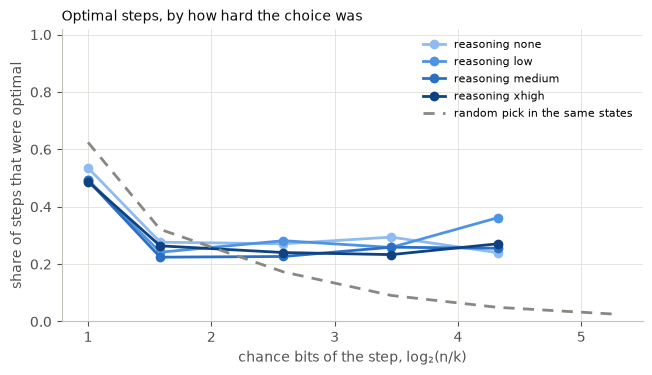

In [5]:
step_rows = []
for x in games:
    t = tasks[x["task"]]
    steps, _ = score_actions(oracles[t["target"]], t["start"], [tuple(a) for a in x["actions"]])
    for s in steps:
        if s["n_optimal"] and s["action"] != "invalid":
            step_rows.append({"level": x["reasoning_effort"], "chance_bits": s["chance_bits"], "optimal": s["optimal"],
                              "random_rate": s["n_optimal"] / s["n_actions"], "action": s["action"]})
steps_df = pd.DataFrame(step_rows)
edges = [0, 1, 2, 3, 4, 5, 6, 8, 20]
steps_df["bin"] = pd.cut(steps_df.chance_bits, edges, include_lowest=True)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for lvl in levels_present:
    m = steps_df[steps_df.level == lvl].groupby("bin", observed=True).agg(x=("chance_bits", "median"), y=("optimal", "mean"), n=("optimal", "size"))
    m = m[m.n >= 20]
    ax.plot(m.x, m.y, marker="o", color=colours[lvl], label=f"reasoning {lvl}")
r = steps_df.groupby("bin", observed=True).agg(x=("chance_bits", "median"), y=("random_rate", "mean"))
ax.plot(r.x, r.y, color=MUTED, linestyle=(0, (4, 3)), label="random pick in the same states")
ax.set(xlabel="chance bits of the step, log₂(n/k)", ylabel="share of steps that were optimal", ylim=(0, 1.02))
ax.legend(fontsize=8)
ax.set_title("Optimal steps, by how hard the choice was", loc="left")
style.save(fig, f"{MODEL_NAME}_by_choice")
steps_df.groupby(["level", "action"]).optimal.agg(["mean", "size"]).unstack("action").round(2)

## Why the model scrolls

Lost games are mostly scrolling, which can mean two different things. The model may scroll because nothing useful is
in view, which is sensible on long pages with few good links. Or it may scroll past links that would bring it
closer. To tell these apart we label every state the model was in by what it could see: the target's own link, a
link to a page closer to the target in the clicks model (one click fewer to go), or neither. We then measure how
often the model clicked in each kind of state, and how often its clicks went to a closer page compared with a
random click among the same links (*random_click_closer*, the share of visible links that lead closer). The start
pages themselves are described first, since they set how
far a player must scroll before a good link appears.

Start pages of the 42 tasks (medians):


,d_star,parts,parts with a closer link,first part with a closer link,step budget
median,3.0,17.0,0.17,1.0,22.0


states  clicked  scrolled  clicked_closer  \
level  in view                                                     
none   closer link        834     0.25      0.74            0.17   
       no closer link    1784     0.09      0.89            0.00   
       target link         34     1.00      0.00            1.00   
low    closer link        760     0.15      0.83            0.12   
       no closer link    1888     0.03      0.95            0.00   
       target link         32     1.00      0.00            1.00   
medium closer link        715     0.13      0.85            0.10   
       no closer link    1996     0.03      0.96            0.00   
       target link         24     1.00      0.00            1.00   
xhigh  closer link        774     0.17      0.81            0.12   
       no closer link    1866     0.04      0.95            0.00   
       target link         32     1.00      0.00            1.00   

                       random_click_closer  closer among its clicks  
level  in view                                                       
none   closer link                    0.52                     0.68  
       no closer link                 0.00                     0.00  
       target link                    0.37                     1.00  
low    closer link                    0.54                     0.79  
       no closer link                 0.00                     0.00  
       target link                    0.34                     1.00  
medium closer link                    0.51                     0.81  
       no closer link                 0.00                     0.00  
       target link                    0.36                     1.00  
xhigh  closer link                    0.49                     0.74  
       no closer link                 0.00                     0.00  
       target link                    0.36                     1.00

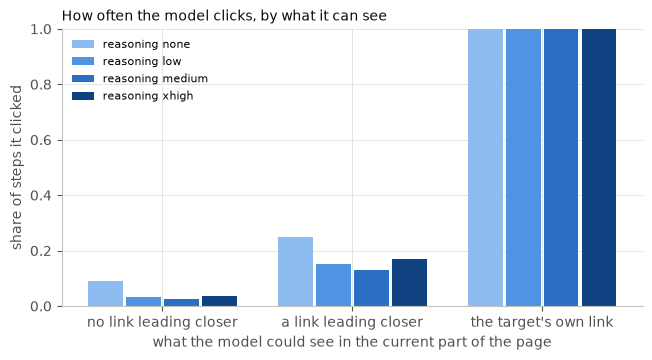

In [6]:
start_pages = []
for t in tasks.values():
    o, p = oracles[t["target"]], t["start"]
    k = world.n_chunks(p)
    has = [any(0 <= o.d[q] < o.d[p] for q in world.chunk_links[p][c]) for c in range(k)]
    start_pages.append({"d_star": t["d_star"], "parts": k, "parts with a closer link": np.mean(has),
                        "first part with a closer link": has.index(True) + 1, "step budget": 2 * t["V_star"] + 10})
start_pages = pd.DataFrame(start_pages)
print("Start pages of the 42 tasks (medians):")
display(start_pages.median().round(2).to_frame("median").T)

seen = []
for x in games:
    t = tasks[x["task"]]
    o = oracles[t["target"]]
    steps, _ = score_actions(o, t["start"], [tuple(a) for a in x["actions"]])
    clicks_at = [s["step"] for s in steps if s["action"] == "click"]
    for s in steps:
        p, vis = s["page"], world.chunk_links[s["page"]][s["chunk"]]
        view = ("target link" if o.target in vis else
                "closer link" if any(0 <= o.d[q] < o.d[p] for q in vis) else "no closer link")
        seen.append({"level": x["reasoning_effort"], "in view": view, "clicked": s["action"] == "click",
                     "scrolled": s["action"].startswith("scroll"),
                     "clicked closer": s["action"] == "click" and o.d[s["to_page"]] < o.d[p],
                     "closer share of links": np.mean([0 <= o.d[q] < o.d[p] for q in vis]) if vis else np.nan})
seen = pd.DataFrame(seen)
views = ["no closer link", "closer link", "target link"]
clicked = seen.groupby(["in view", "level"]).clicked.mean().unstack("level")[levels_present].reindex(views)
table = seen.groupby(["level", "in view"]).agg(states=("clicked", "size"), clicked=("clicked", "mean"), scrolled=("scrolled", "mean"),
                                              clicked_closer=("clicked closer", "mean"), random_click_closer=("closer share of links", "mean"))
table["closer among its clicks"] = table.clicked_closer / table.clicked
display(table.reindex(levels_present, level="level").round(2))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
width = 0.8 / len(levels_present)
for i, lvl in enumerate(levels_present):
    xs = np.arange(len(views)) + (i - (len(levels_present) - 1) / 2) * width
    ax.bar(xs, clicked[lvl], width * 0.92, color=colours[lvl], label=f"reasoning {lvl}")
ax.set_xticks(range(len(views)), ["no link leading closer", "a link leading closer", "the target's own link"])
ax.set(xlabel="what the model could see in the current part of the page", ylabel="share of steps it clicked", ylim=(0, 1))
ax.legend(fontsize=8, loc="upper left")
ax.set_title("How often the model clicks, by what it can see", loc="left")
style.save(fig, f"{MODEL_NAME}_clicks_by_view")

The pace of a game: the step of the first click, the share of games that read the whole start page before clicking
(or never clicked), and the share of games with no click at all.

In [7]:
pace = []
for x in games:
    t = tasks[x["task"]]
    first = next((i for i, a in enumerate(x["actions"], 1) if a[0] == "click"), None)
    chunks, chunk = [0], 0
    for a in x["actions"][: (first or len(x["actions"]) + 1) - 1]:
        chunk += {"scroll_down": 1, "scroll_up": -1}.get(a[0], 0)
        chunks.append(chunk)
    pace.append({"level": x["reasoning_effort"], "first click": first,
                 "read the whole start page first": max(chunks) == world.n_chunks(t["start"]) - 1,
                 "no click": first is None})
pace = pd.DataFrame(pace)
pace.groupby("level").agg(**{"median step of first click": ("first click", "median"),
                             "read the whole start page first": ("read the whole start page first", "mean"),
                             "no click": ("no click", "mean")}).reindex(levels_present).round(2)

,median step of first click,read the whole start page first,no click
level,,,
none,8.0,0.45,0.18
low,4.5,0.40,0.25
medium,4.0,0.46,0.27
xhigh,2.5,0.36,0.22


## Does more reasoning help on the same tasks?

A paired comparison: for each task, the mean success over its 3 runs at one level minus that at the level without
reasoning. Positive values mean reasoning helped on that task. The interval is a 95% bootstrap interval over tasks
(10,000 resamples of the 42 tasks), so it shows how much the mean change could move with a different draw of tasks.

In [8]:
per_task = df.groupby(["task", "level"]).success.mean().unstack("level")
def change(diff, n=10_000):
    rng = np.random.default_rng(0)
    boot = rng.choice(diff.values, (n, len(diff))).mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return f"{diff.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]"

if "none" in per_task:
    paired = pd.DataFrame({lvl: {
        "tasks better": int((per_task[lvl] > per_task["none"]).sum()),
        "tasks worse": int((per_task[lvl] < per_task["none"]).sum()),
        "mean change in success": change(per_task[lvl] - per_task["none"]),
    } for lvl in levels_present if lvl != "none"})
    display(paired)

,low,medium,xhigh
tasks better,5,4,7
tasks worse,7,11,9
mean change in success,"-0.016 [-0.095, +0.063]","-0.079 [-0.159, -0.008]","-0.016 [-0.087, +0.056]"


## Where games go wrong

The first step with regret, and how games that did not arrive ended: by running out of steps while scrolling, while
clicking around, or stuck on invalid actions.

In [9]:
lost = df[~df.success].copy()
lost["mostly"] = np.select([lost.scrolls > lost.steps / 2, lost.invalid > lost.steps / 4], ["scrolling", "invalid actions"], "clicking")
display(pd.crosstab(lost.level, lost.mostly).reindex(levels_present))
df.groupby("level").first_error.describe()[["count", "50%", "mean"]].reindex(levels_present).round(1)

mostly,clicking,scrolling
level,,
none,4,88
low,0,94
medium,0,102
xhigh,0,94


,count,50%,mean
level,,,
none,112.0,2.0,1.5
low,117.0,1.0,1.5
medium,117.0,2.0,1.5
xhigh,115.0,2.0,1.6
